# v7b：攻击的时间顺序变量（老师的建议）— 在 v7 的三鱼状态上加"谁先冲、何时最近、对方怎么反应"

**目的**：老师的意见——6 变量描述"配置"，但攻击需要"配置按什么顺序、多快变化"。v7b 在 v7 的三鱼状态上加入攻击的**时间顺序变量**（在几十到几百 ms 的窗口里）：
1. **谁先冲**：主角朝另一条的接近速度（速度在两鱼连线上的分量）在窗口内的峰值，以及主角与另一条峰值之差（主角先冲 / 对方先冲 / 都没冲）。
2. **何时最近**：窗口内最小距离和它出现的时刻（在当前帧之前 / 附近 / 之后）。
3. **对方的反应**：最接近之后一个窗口内，另一条鱼的转向角和速度变化。

这些变量用 **SG 5 帧**（≈ 0.03 s）平滑的坐标计算，因为最短的攻击（0.05–0.08 s）比 v3b 的 11 帧平滑还短；三鱼状态本身仍用 v3b 的 11 帧。窗口在 50 / 100 / 200 ms 中按训练集留一录像（LOEO）AP 选。其余设定（训练 / 测试、轮流主角、镜像、回退打分、标注规则）与 v7 相同；只做攻击。

**方法**（每个目标都用同一批帧、同一套打分→平滑→阈值流程）：

| 名称 | 状态 |
|---|---|
| B | v3b 的配对 6 变量微状态（qc：F–主角；攻击：主角–另一条），基准 |
| B+rot | B + 主角累积回转角（仅 qc；老师建议的直接对照） |
| T | 三鱼状态（分层回退） |
| T+rot | T + 主角累积回转角（仅 qc） |
| T+rot+depth | T+rot + 雌鱼深度（仅 qc；检验绝对位置） |
| T+seq | T + 攻击时间顺序变量（仅攻击，v7b / v7c） |
| C | Infomap 簇（τ 帧后的转移，训练集）：qc 用 T+rot 的完整状态，攻击用 T（v7b / v7c 为 T+seq）的完整状态；τ ∈ {7, 17} 按训练集 LOEO AP 选 |

**评估**（每个测试录像）：AP、帧精确率、帧召回率、检出 bout / 标注 bout、误报区间 / 配对·分钟（训练集 F1 最大的阈值）；另外按老师的要求，**在相同误报率下比较**：在训练集上把阈值定到 0.25 / 0.5 / 1 个误报 / 配对·分钟，固定后在测试集上数检出的 bout，并画"检出 bout 数–误报 / 分钟"曲线。

## 参数

数据划分、BORIS 类别、三鱼变量的分档、回退顺序、方法定义、Infomap 和评估设置都在这里。分档边界单位：距离 mm、速度 mm/s、角度在 `scripts/analysis/trio_state.bin_values` 里按 45° / 90° 分。所有分档都多一个"未定义"档（两条鱼上下重叠时水平角没有定义）。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

VARIANT = "v7b"
RUN_NAME = "20261110_trio_attack_sequence_v7b"
SOURCE_RUN = "20261108_pair_state6d_clean_sw11_v3b"   # read: params.json (cleaning) and the 6-variable bin edges (B)
OUTPUT_ROOT = None       # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC", "20251220_E_1_1_FCMC", "20251220_E_1_2_FCMC", "20251220_E_1_3_FCMC"]
REVIEW_MIN_WATCHED_PCT = 99.0    # a recording is used only if its ID-pass summary says at least this much was watched
TARGETS = ["att"]
USE_SEQ = True              # attack time-order variables (v7b / v7c)
DPI = 200
THUMB_WIDTH = 900

LABEL_CLASSES = {"wrap": ["wrap"], "qc": ["quick circle", "incomplete qc", "courtship"],
                 "att": ["attack", "attempted att", "dash"]}
COPIES = [("M1", "M2"), ("M2", "M1")]   # (focal, rival): every frame twice, each male focal once
EVAL_COPIES = {"qc": [0, 1], "att": [0]}  # att labels are symmetric -> one copy per frame, as v6 (M1M2)

# --- three-fish variables and bins
D_EDGES = [0, 10, 20, 40, float("inf")]
DZ_EDGES = [-float("inf"), -20, 20, float("inf")]
SP_EDGES = [0, 60, float("inf")]
MD_EDGES = [0, 15, 40, float("inf")]
TRIO_SPECS = {
    "fD": ("lin", D_EDGES), "fdz": ("lin", DZ_EDGES), "fthF": ("half4", None), "fthM": ("circ4", None), "fsp": ("lin", SP_EDGES),
    "rD": ("lin", D_EDGES), "rdz": ("lin", DZ_EDGES), "rthF": ("circ4", None), "rthM": ("circ4", None), "rsp": ("lin", SP_EDGES),
    "Fsp": ("lin", SP_EDGES), "mD": ("lin", MD_EDGES), "mthf": ("circ4", None), "mthr": ("circ4", None),
}
ROT_WINDOWS_S = [0.5, 1.0, 2.0]       # candidate windows; chosen on train (LOEO AP of B+rot)
ROT_EDGES = [0, 45, 90, float("inf")]  # degrees
DEPTH_EDGES = [-float("inf"), 1 / 3, 2 / 3, float("inf")]   # female pectoral height as a fraction of the train z range
DEPTH_PERCENTILES = (0.5, 99.5)

# --- attack time-order variables (USE_SEQ)
SEQ_SMOOTH_WINDOW = 5                 # SG window for these variables only (frames)
SEQ_WINDOWS_S = [0.05, 0.1, 0.2]      # candidate windows; chosen on train (LOEO AP of T+seq)
SEQ_SPECS = {
    "lead": ("lin", [-float("inf"), 100, 300, float("inf")]),          # focal peak approach speed toward the rival (mm/s)
    "who": ("lin", [-float("inf"), -100, 100, float("inf")]),          # focal peak - rival peak approach speed (mm/s)
    "dmin": ("lin", [0, 5, 15, float("inf")]),                          # minimum 3D distance in the window (mm)
    "tmin": ("lin", [-float("inf"), -1 / 3, 1 / 3, float("inf")]),     # time of the minimum / half-window (-1 = start, +1 = end)
    "turn": ("lin", [0, 30, 90, float("inf")]),                         # rival heading change after the minimum (deg)
    "dsp": ("lin", [-float("inf"), 50, 150, float("inf")]),            # rival speed increase after the minimum (mm/s)
}

FOC = ["fD", "fdz", "fthF", "fthM", "fsp"]
RIV = ["rD", "rdz", "rthF", "rthM", "rsp"]
MMV = ["mD", "mthf", "mthr"]


def qc_levels(extra):
    # finest first; drop depth and M-M angles, then rival heading/speed, then rival direction/height
    e1 = [x for x in extra if x != "depth"]
    return [FOC + RIV + ["Fsp"] + MMV + list(extra), FOC + RIV + ["Fsp", "mD"] + e1,
            FOC + ["rD", "rdz", "rthF", "Fsp", "mD"] + e1, FOC + ["rD", "Fsp", "mD"] + e1, FOC + e1]


def att_levels(extra):
    # finest first; keep the M-M variables and both male speeds to the end; time-order variables
    # (if any) are dropped last, in two steps (keep lead/who/dmin/turn, then who/dmin)
    ex = list(extra)
    s4 = [x for x in ("lead", "who", "dmin", "turn") if x in ex]
    s2 = [x for x in ("who", "dmin") if x in ex]
    lv = [FOC + RIV + ["Fsp"] + MMV + ex, FOC + RIV + MMV + ex,
          ["fD", "fdz", "fthM", "fsp", "rD", "rdz", "rthM", "rsp"] + MMV + ex,
          ["fD", "fsp", "rD", "rsp"] + MMV + ex, ["fsp", "rsp"] + MMV + ex,
          ["mD", "fsp", "rsp"] + s4, ["mD", "fsp", "rsp"] + s2, ["mD", "fsp", "rsp"]]
    out = []
    for keys in lv:   # drop repeated levels (no time-order variables)
        if not out or set(keys) != set(out[-1]):
            out.append(keys)
    return out


METHODS = {
    "qc": {"B": {"kind": "B", "extra": []}, "B+rot": {"kind": "B", "extra": ["rot"]},
           "T": {"kind": "T", "extra": []}, "T+rot": {"kind": "T", "extra": ["rot"]},
           "T+rot+depth": {"kind": "T", "extra": ["rot", "depth"]}, "C": {"kind": "C", "on": "T+rot"}},
    "att": {"B": {"kind": "B", "extra": []}, "T": {"kind": "T", "extra": []},
            **({"T+seq": {"kind": "T", "extra": list(SEQ_SPECS)}} if USE_SEQ else {}),
            "C": {"kind": "C", "on": "T+seq" if USE_SEQ else "T"}},
}
SMOOTH = {"qc": 124, "att": 5}          # centred smoothing of the frame scores (frames), as v3b / v6
PRIOR_FRAMES = 50.0
FA_TARGETS = [0.25, 0.5, 1.0]           # false alarms / pair-min fixed on train for the matched comparison

# --- Infomap (C)
TAUS = [7, 17]
N_TRIALS = 200
INFOMAP_SEED = 20261107
INFOMAP_WORKERS = 4

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; {VARIANT} run {RUN_NAME}; targets {TARGETS}")

37 parameters; v7b run 20261110_trio_attack_sequence_v7b; targets ['att']


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录，读 v3b 的清洗参数和 6 变量分格边界。新的计算逻辑在 `scripts/analysis/trio_state.py`（单元测试 `tests/test_trio_state.py`）：三鱼变量、镜像、累积回转角、分档、分层回退打分、把簇映射到训练中没出现过的状态、向量化的误报 / bout 计数。

In [2]:
import os
import sys
import time
import json
import platform

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, display
from scipy import sparse
from sklearn.metrics import average_precision_score, precision_recall_curve
from concurrent.futures import ProcessPoolExecutor

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis import trio_state as TS
from scripts.analysis.behavior_dataset import find_package, resolve_roots

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
SRC = OUT_ROOT / SOURCE_RUN
V3B = json.loads((SRC / "params.json").read_text())["parameters"]
_edge_files = sorted((SRC / "data").glob("02_bin_edges__all__*__train.json"))
assert len(_edge_files) == 1, _edge_files
EDGES_JSON = json.loads(_edge_files[0].read_text())
EDGES = [np.asarray(x, dtype=np.float64) for x in EDGES_JSON["edges"]]
CONTACT_ID = int(EDGES_JSON["contact_state"])
N_B_STATES = int(EDGES_JSON["n_states"])
METHOD_COLOR = {"B": "#9e9e9e", "B+rot": "#4C78A8", "T": "#54A24B", "T+rot": "#2ca02c", "T+rot+depth": "#B279A2",
                "T+seq": "#E45756", "C": "#ff7f0e"}


def _allow_listed(experiment, final):
    if experiment not in TRAIN_EXPERIMENTS + TEST_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def show(p):
    display(IPImage(filename=str(L.thumbs / p.name)))


def review_status(e):
    # (usable?, reason) from the ID-pass summary of the experiment's review package
    try:
        pkg = find_package(REVIEW_ROOT, e)
    except BaseException as ex:   # find_package raises SystemExit
        return False, f"no ID-pass package ({ex})"
    p = Path(pkg) / "id_pass" / "id_pass_summary.json"
    if not p.exists():
        return False, "ID-pass not finished (no id_pass_summary.json)"
    s = json.loads(p.read_text(encoding="utf-8"))
    w = float(s.get("watched_pct", 0.0))
    return w >= REVIEW_MIN_WATCHED_PCT, f"watched {w:.1f}%, usable {s.get('usable_pct')}%"


SKIPPED = {}
for e in list(TEST_EXPERIMENTS):
    ok, why = review_status(e)
    if not ok:
        SKIPPED[e] = why
        TEST_EXPERIMENTS.remove(e)
for e in TRAIN_EXPERIMENTS:
    ok, why = review_status(e)
    assert ok, f"training experiment {e}: {why}"
print("train:", [exp_short(e) for e in TRAIN_EXPERIMENTS])
print("test: ", [exp_short(e) for e in TEST_EXPERIMENTS])
print("skipped (rerun this notebook when their ID-pass is done):", SKIPPED or "none")
L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "variant": VARIANT, "date": time.strftime("%Y-%m-%d %H:%M:%S"),
                        "output_dir": str(L.root), "source_dir": str(SRC), "platform": platform.platform(),
                        "test_used": TEST_EXPERIMENTS, "test_skipped": SKIPPED})
print("output folder", L.root)

train: ['K_1_1', 'K_1_2', 'P_1_1', 'P_1_2']
test:  ['K_1_3', 'P_1_3', 'E_1_1', 'E_1_2', 'E_1_3']
skipped (rerun this notebook when their ID-pass is done): none
output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261110_trio_attack_sequence_v7b


## Step 0 — 预处理：每个录像、每个副本（主角 = M1 / M2）的三鱼变量

1. 读审核后的 3D 坐标（`load_trial(final=True)`：只用 ID-pass 看过且可用的帧），按 v3b 清洗：去异常骨架（嘴–胸鳍 > 12 mm 或胸鳍–尾 > 25 mm）→ ≤ 5 帧插值（不跨审核屏蔽帧）→ SG 11 帧平滑；胸鳍速度同 v3b。
2. 每个副本 (F, 主角, 另一条)：`trio_variables` → 镜像（主角放到雌鱼的一侧）；主角累积回转角（`ROT_WINDOWS_S` 三个窗口都算）；雌鱼胸鳍高度；B 用的 v3b 6 变量微状态（qc：F–主角；攻击：主角–另一条，含 contact 状态）。
3. 画图用：主角和另一条在雌鱼坐标系里的位置（原点 = 雌鱼胸鳍，x' = 雌鱼朝向，未镜像），以及三条鱼在水槽里的绝对坐标。
4. 标签：qc = F–主角配对的 BORIS qc（任一方向）；att = 主角–另一条的 BORIS att。审核不可用的帧、三鱼的距离 / 速度不全的帧 → 不参与评估（-1）。

5. **攻击时间顺序变量**（`USE_SEQ`）：用 SG `SEQ_SMOOTH_WINDOW` 帧平滑的坐标另算，见 Step 0c。

In [3]:
# Step 0: per experiment and copy, the three-fish variables, rotation, depth, v3b pair states and labels.
FISH_IX = {f: i for i, f in enumerate(P4.FISH)}


def clean_nodes(tr, window):
    nodes = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    hp = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)
    pt = np.linalg.norm(nodes[:, :, P4.PEC] - nodes[:, :, P4.TAIL], axis=-1)
    bad = (np.isfinite(hp) & (hp > V3B["HEAD_PEC_MAX_MM"])) | (np.isfinite(pt) & (pt > V3B["PEC_TAIL_MAX_MM"]))
    nodes[bad] = np.nan
    nodes = M.fill_gaps(nodes, V3B["FILL_LIMIT"], blocked)
    return P4.smooth_tracks(nodes, window, V3B["SG_ORDER"])


def v3b_pair_state(nodes, blocked, speed, a, b):
    # exactly v3b Step 0 + Step 2 for the ordered pair a -> b (6 variables, contact state)
    ia, ib = FISH_IX[a], FISH_IX[b]
    v4 = P4.pair_variables(nodes, a, b, V3B["MIN_XY_MM"])
    pa, pb = nodes[:, ia, P4.PEC], nodes[:, ib, P4.PEC]
    d_xy = np.linalg.norm(pb[:, :2] - pa[:, :2], axis=1)
    dz = pa[:, 2] - pb[:, 2]
    sp = speed[:, [ia, ib]]
    v = np.column_stack([v4, sp])
    full = np.isfinite(v).all(axis=1)
    fin = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3)) & ~blocked
    contact = (fin & ~full & np.isfinite(sp).all(axis=1) & np.isfinite(dz) & np.isfinite(d_xy)
               & bool(V3B["CONTACT_STATE"]))
    v[contact, 0], v[contact, 1] = d_xy[contact], dz[contact]
    _b, state, _w = P4.encode(v.astype(np.float32).astype(np.float64), EDGES)
    state[contact] = CONTACT_ID
    state[~(full | contact)] = -1
    return state.astype(np.int32)


def in_female_frame(nodes, p):
    # coordinates of points p (T, 3) with origin = female pectoral point and x' = female heading (horizontal)
    pF = nodes[:, 0, P4.PEC]
    h = nodes[:, 0, P4.HEAD] - pF
    a = np.arctan2(h[:, 1], h[:, 0])
    c, s = np.cos(a), np.sin(a)
    r = p - pF
    return np.column_stack([c * r[:, 0] + s * r[:, 1], -s * r[:, 0] + c * r[:, 1], r[:, 2]])


SEQ_ROWS = {}   # filled in Step 0c (USE_SEQ)


def experiment_rows(e):
    tr = M.load_trial(e, final=True)
    fps = float(tr["fps"])
    frames = np.asarray(tr["frames"], np.int64)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    nodes = clean_nodes(tr, V3B["SMOOTH_WINDOW"])
    speed = np.column_stack([P4.fish_speed(nodes[:, i, P4.PEC], fps, V3B["SPEED_HALF_WINDOW"]) for i in range(3)])
    bouts = M.bouts_of(e)
    out = []
    for ci, (f, r) in enumerate(COPIES):
        v = TS.trio_variables(nodes, speed, f, r, V3B["MIN_XY_MM"])
        vm, flip = TS.mirror(v)
        row = {k: np.asarray(x, np.float32) for k, x in vm.items()}
        for w_s in ROT_WINDOWS_S:
            w = max(2, int(round(w_s * fps / 2)) * 2)
            row[f"rot_{w_s}"] = TS.line_rotation(nodes, f, w, V3B["MIN_XY_MM"]).astype(np.float32)
        pf = in_female_frame(nodes, nodes[:, FISH_IX[f], P4.PEC])
        pr = in_female_frame(nodes, nodes[:, FISH_IX[r], P4.PEC])
        for j, ax in enumerate("xyz"):
            row[f"focal_{ax}F"] = pf[:, j].astype(np.float32)
            row[f"rival_{ax}F"] = pr[:, j].astype(np.float32)
            row[f"F_{ax}"] = nodes[:, 0, P4.PEC, j].astype(np.float32)
            row[f"focal_{ax}"] = nodes[:, FISH_IX[f], P4.PEC, j].astype(np.float32)
        row["B_qc"] = v3b_pair_state(nodes, blocked, speed, "F", f)
        row["B_att"] = v3b_pair_state(nodes, blocked, speed, f, r)
        need = ["fD", "fdz", "fsp", "rD", "rdz", "rsp", "mD", "Fsp"]
        valid = ~blocked & np.all([np.isfinite(v[k]) for k in need], axis=0)
        lab_qc = P4.base_class(P4.pair_frame_labels(bouts, "F", f, frames, LABEL_CLASSES, directed=True))
        lab_att = P4.base_class(P4.pair_frame_labels(bouts, f, r, frames, LABEL_CLASSES, directed=True))
        y_qc, y_att = P4.detection_target(lab_qc, "qc"), P4.detection_target(lab_att, "att")
        y_qc[~valid] = -1
        y_att[~valid] = -1
        row.update({"valid": valid, "blocked": blocked, "y_qc": y_qc, "y_att": y_att, "flip": flip,
                    "frame": frames, "copy": np.full(len(frames), ci, np.int8)})
        out.append(row)
    return out, fps, float((~blocked).mean())


def build_set(exps):
    parts, fps_of, info = [], {}, []
    for ei, e in enumerate(exps):
        t0 = time.time()
        rows, fps, usable = experiment_rows(e)
        fps_of[e] = fps
        for row in rows:
            row["exp"] = np.full(len(row["frame"]), ei, np.int16)
            parts.append(row)
        r0 = rows[0]
        info.append({"experiment": e, "frames": len(r0["frame"]), "fps": fps, "usable_percent": 100 * usable,
                     "three_fish_valid_percent": 100 * r0["valid"].mean(),
                     "qc_bouts_labelled_frames": int(sum((r["y_qc"] == 1).sum() for r in rows)),
                     "att_labelled_frames": int((r0["y_att"] == 1).sum()), "seconds": time.time() - t0})
        print(f"{exp_short(e)}: {len(r0['frame'])} frames, usable {100 * usable:.1f}%, three-fish valid "
              f"{100 * r0['valid'].mean():.1f}%, qc frames {info[-1]['qc_bouts_labelled_frames']}, "
              f"att frames {info[-1]['att_labelled_frames']} ({time.time() - t0:.0f} s)", flush=True)
    D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    D["block"] = D["exp"].astype(np.int64) * 10 + D["copy"].astype(np.int64)
    return D, fps_of, pd.DataFrame(info)


DATA, FPS_OF, INFO = {}, {}, []
for sn, exps in (("train", TRAIN_EXPERIMENTS), ("test", TEST_EXPERIMENTS)):
    DATA[sn], f_, inf_ = build_set(exps)
    DATA[sn]["exp_names"] = list(exps)
    FPS_OF.update(f_)
    INFO.append(inf_.assign(set=sn))
INFO = pd.concat(INFO, ignore_index=True)
L.save_csv(INFO, "00", "experiments", "all", "base", "all")

# depth = female pectoral height as a fraction of the train z range of all three fish (copies cover M1 and M2)
_z = np.concatenate([DATA["train"]["F_z"], DATA["train"]["focal_z"]])
Z_LO, Z_HI = np.nanpercentile(_z, DEPTH_PERCENTILES)
_x = np.concatenate([DATA["train"]["F_x"], DATA["train"]["focal_x"]])
_y = np.concatenate([DATA["train"]["F_y"], DATA["train"]["focal_y"]])
XY_LO = np.array([np.nanpercentile(_x, DEPTH_PERCENTILES[0]), np.nanpercentile(_y, DEPTH_PERCENTILES[0])])
XY_HI = np.array([np.nanpercentile(_x, DEPTH_PERCENTILES[1]), np.nanpercentile(_y, DEPTH_PERCENTILES[1])])
for D in DATA.values():
    D["depth"] = ((D["F_z"] - Z_LO) / (Z_HI - Z_LO)).astype(np.float32)
print(f"train tank extent ({DEPTH_PERCENTILES} percentiles): x {XY_LO[0]:.0f}-{XY_HI[0]:.0f}, "
      f"y {XY_LO[1]:.0f}-{XY_HI[1]:.0f}, z {Z_LO:.0f}-{Z_HI:.0f} mm")
print(INFO.round(1).to_string(index=False))

K_1_1: 348600 frames, usable 96.6%, three-fish valid 96.4%, qc frames 12584, att frames 358 (4 s)


K_1_2: 348600 frames, usable 94.0%, three-fish valid 93.9%, qc frames 13930, att frames 407 (4 s)


P_1_1: 348600 frames, usable 94.7%, three-fish valid 94.5%, qc frames 3045, att frames 255 (4 s)


P_1_2: 348600 frames, usable 96.1%, three-fish valid 95.9%, qc frames 2524, att frames 304 (4 s)


K_1_3: 348600 frames, usable 93.0%, three-fish valid 92.9%, qc frames 12765, att frames 149 (4 s)


P_1_3: 348600 frames, usable 93.8%, three-fish valid 93.7%, qc frames 5526, att frames 439 (4 s)


E_1_1: 348600 frames, usable 93.5%, three-fish valid 93.3%, qc frames 996, att frames 0 (4 s)


E_1_2: 348600 frames, usable 96.7%, three-fish valid 96.6%, qc frames 1541, att frames 418 (4 s)


E_1_3: 348600 frames, usable 94.3%, three-fish valid 94.2%, qc frames 2512, att frames 114 (4 s)


  csv data/00_experiments__all__base__all.csv  rows 9


train tank extent ((0.5, 99.5) percentiles): x 1-187, y 3-190, z -6-185 mm
         experiment  frames   fps  usable_percent  three_fish_valid_percent  qc_bouts_labelled_frames  att_labelled_frames  seconds   set
20251225_K_1_1_FCMC  348600 166.0            96.6                      96.4                     12584                  358      3.8 train
20251225_K_1_2_FCMC  348600 166.0            94.0                      93.9                     13930                  407      4.0 train
20260112_P_1_1_FCMC  348600 166.0            94.7                      94.5                      3045                  255      3.9 train
20260113_P_1_2_FCMC  348600 166.0            96.1                      95.9                      2524                  304      3.8 train
20251225_K_1_3_FCMC  348600 166.0            93.0                      92.9                     12765                  149      3.8  test
20260112_P_1_3_FCMC  348600 166.0            93.8                      93.7                      

## Step 0b — 检查：B 的微状态和 v3b 完全一致

本 notebook 从原始轨迹重新计算 B 的 6 变量微状态。和 v3b 保存的微状态比较（训练集第一个录像和测试集的 K_1_3、P_1_3）：主角 = M1 的 qc 副本 = v3b 的 FM1，攻击副本 = v3b 的 M1M2。必须 100% 相同。

In [4]:
# Step 0b: the B microstates computed here must equal the v3b files.
def v3b_states(unit, set_name, exp, copy_name):
    hits = sorted((SRC / "data").glob(f"02_microstates__{unit}__*__{set_name}.npz"))
    assert len(hits) == 1, hits
    with np.load(hits[0]) as z:
        names, copies = list(z["exp_names"]), list(z["copy_names"])
        if exp not in names:
            return None
        m = (z["exp"] == names.index(exp)) & (z["copy"] == copies.index(copy_name))
        return z["state"][m]


rows = []
for sn, D in DATA.items():
    for e in D["exp_names"]:
        ref_set = "train" if e in ("20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC") else "test"
        for unit, key, cname in (("FM", "B_qc", "FM1"), ("MM", "B_att", "M1M2")):
            ref = v3b_states(unit, ref_set, e, cname)
            if ref is None:
                continue
            m = (D["exp"] == D["exp_names"].index(e)) & (D["copy"] == 0)
            mine = D[key][m]
            rows.append({"experiment": exp_short(e), "unit": unit, "frames": len(mine),
                         "identical_percent": 100 * float((mine == ref).mean()) if len(mine) == len(ref) else np.nan})
CHECK = pd.DataFrame(rows)
L.save_csv(CHECK, "00b", "check_v3b_states", "all", "base", "all")
print(CHECK.to_string(index=False))
assert (CHECK.identical_percent > 99.99).all(), "B microstates differ from v3b"

  csv data/00b_check_v3b_states__all__base__all.csv  rows 12
experiment unit  frames  identical_percent
     K_1_1   FM  348600              100.0
     K_1_1   MM  348600              100.0
     K_1_2   FM  348600              100.0
     K_1_2   MM  348600              100.0
     P_1_1   FM  348600              100.0
     P_1_1   MM  348600              100.0
     P_1_2   FM  348600              100.0
     P_1_2   MM  348600              100.0
     K_1_3   FM  348600              100.0
     K_1_3   MM  348600              100.0
     P_1_3   FM  348600              100.0
     P_1_3   MM  348600              100.0


## Step 0c — 攻击时间顺序变量（老师的建议）

用 SG `SEQ_SMOOTH_WINDOW` = 5 帧平滑的坐标（其余清洗同 v3b）。对每个副本（主角 → 另一条）和每个候选窗口 W（`SEQ_WINDOWS_S` = 50 / 100 / 200 ms），在以当前帧为中心、长 W 的窗口里：

| 变量 | 定义 | 对应老师的 |
|---|---|---|
| `lead` | 主角朝另一条的接近速度（主角速度在 主角→另一条 方向上的分量，mm/s）在窗口前半段的峰值 | ① 哪条雄鱼朝对方加速 |
| `who` | 窗口前半段 主角峰值 − 另一条峰值（> 100：主角先冲；< −100：对方先冲；之间：都差不多） | ① |
| `dmin` | 窗口内 3D 胸鳍距离的最小值 | ② 何时最接近 |
| `tmin` | 最小距离出现的时刻（−1 = 窗口开始，0 = 当前帧，+1 = 窗口结束） | ② |
| `turn` | 最接近之后半个窗口内，另一条鱼水平朝向的变化（度） | ③ 对方是否转向 |
| `dsp` | 最接近之后半个窗口内，另一条鱼速度的最大增加（mm/s） | ③ 对方是否加速 |

窗口超出连续有效段的帧，这些变量记为未定义（单独一档）。分档边界见参数。

In [5]:
# Step 0c: attack time-order variables from lightly smoothed coordinates.
from numpy.lib.stride_tricks import sliding_window_view


def _win(x, w):
    # centred windows of length w + 1 (NaN-padded) -> (T, w + 1)
    h = w // 2
    xp = np.concatenate([np.full(h, np.nan), x, np.full(h, np.nan)])
    return sliding_window_view(xp, w + 1)


def seq_variables(nodes, fps, f, r, w):
    i_f, i_r = FISH_IX[f], FISH_IX[r]
    pf, pr = nodes[:, i_f, P4.PEC], nodes[:, i_r, P4.PEC]
    vel = lambda p: np.gradient(p, axis=0) * fps
    u = pr - pf
    dist = np.linalg.norm(u, axis=1)
    u = u / np.where(dist > 0, dist, np.nan)[:, None]
    app_f = np.sum(vel(pf) * u, axis=1)            # focal moving toward the rival (+)
    app_r = -np.sum(vel(pr) * u, axis=1)           # rival moving toward the focal (+)
    hr = nodes[:, i_r, P4.HEAD, :2] - nodes[:, i_r, P4.PEC, :2]
    head_r = np.unwrap(np.nan_to_num(np.arctan2(hr[:, 1], hr[:, 0])))
    head_r[~np.isfinite(hr).all(axis=1)] = np.nan
    sp_r = np.linalg.norm(vel(pr), axis=1)
    h = w // 2
    Wd, Wf, Wr = _win(dist, w), _win(app_f, w), _win(app_r, w)
    ok = np.isfinite(Wd).all(axis=1) & np.isfinite(Wf).all(axis=1) & np.isfinite(Wr).all(axis=1)
    lead = np.nanmax(Wf[:, :h + 1], axis=1)
    who = lead - np.nanmax(Wr[:, :h + 1], axis=1)
    k = np.nanargmin(np.where(np.isfinite(Wd), Wd, np.inf), axis=1)
    dmin = Wd[np.arange(len(k)), k]
    tmin = (k - h) / max(h, 1)
    # rival response in the half window after the minimum
    idx = np.arange(len(dist)) - h + k                      # frame of the minimum
    after = idx[:, None] + np.arange(h + 1)[None, :]
    inside = (after >= 0) & (after < len(dist))
    aa = np.clip(after, 0, len(dist) - 1)
    hd = np.where(inside, head_r[aa], np.nan)
    sp = np.where(inside, sp_r[aa], np.nan)
    turn = np.degrees(np.nanmax(np.abs(hd - hd[:, :1]), axis=1))
    dsp = np.nanmax(sp - sp[:, :1], axis=1)
    ok &= inside.all(axis=1) & np.isfinite(hd).all(axis=1) & np.isfinite(sp).all(axis=1)
    out = {"lead": lead, "who": who, "dmin": dmin, "tmin": tmin, "turn": turn, "dsp": dsp}
    return {k_: np.where(ok, x, np.nan).astype(np.float32) for k_, x in out.items()}


import warnings
for sn, D in DATA.items():
    parts = {w_s: {k: [] for k in SEQ_SPECS} for w_s in SEQ_WINDOWS_S}
    for e in D["exp_names"]:
        tr = M.load_trial(e, final=True)
        fps = float(tr["fps"])
        nodes = clean_nodes(tr, SEQ_SMOOTH_WINDOW)
        for f, r in COPIES:
            for w_s in SEQ_WINDOWS_S:
                w = max(2, int(round(w_s * fps / 2)) * 2)
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", RuntimeWarning)
                    sv = seq_variables(nodes, fps, f, r, w)
                for k in SEQ_SPECS:
                    parts[w_s][k].append(sv[k])
        print(f"{sn} {exp_short(e)}: time-order variables done", flush=True)
    for w_s in SEQ_WINDOWS_S:
        for k in SEQ_SPECS:
            D[f"{k}_{w_s}"] = np.concatenate(parts[w_s][k])
        assert len(D[f"lead_{w_s}"]) == len(D["frame"])
tr_ = DATA["train"]
for w_s in SEQ_WINDOWS_S:
    rows = []
    for k in SEQ_SPECS:
        x = tr_[f"{k}_{w_s}"]
        a, n = (tr_["y_att"] == 1) & (tr_["copy"] == 0), (tr_["y_att"] == 0) & (tr_["copy"] == 0)
        rows.append({"variable": k, "att median": np.nanmedian(x[a]), "none median": np.nanmedian(x[n]),
                     "defined % (att)": 100 * np.isfinite(x[a]).mean()})
    print(f"window {w_s} s (train, copy focal M1):")
    print(pd.DataFrame(rows).round(2).to_string(index=False))

train K_1_1: time-order variables done


train K_1_2: time-order variables done


train P_1_1: time-order variables done


train P_1_2: time-order variables done


test K_1_3: time-order variables done


test P_1_3: time-order variables done


test E_1_1: time-order variables done


test E_1_2: time-order variables done


test E_1_3: time-order variables done


window 0.05 s (train, copy focal M1):
variable  att median  none median  defined % (att)
    lead        3.43     8.370000            96.83
     who       -1.53     2.270000            96.83
    dmin       15.10   127.370003            96.83
    tmin       -0.25     0.250000            96.83
    turn       14.43     1.510000            96.83
     dsp        0.00     5.730000            96.83
window 0.1 s (train, copy focal M1):
variable  att median  none median  defined % (att)
    lead   17.440001    11.510000            95.09
     who  -13.270000     2.760000            95.09
    dmin   13.070000   126.470001            95.09
    tmin   -0.120000     0.380000            95.09
    turn   30.770000     2.440000            95.09
     dsp    0.440000     9.190000            95.09


window 0.2 s (train, copy focal M1):
variable  att median  none median  defined % (att)
    lead   44.189999    15.690000            93.35
     who  -51.680000     3.460000            93.35
    dmin   11.760000   124.389999            93.35
    tmin   -0.060000     0.350000            93.35
    turn   53.110001     4.340000            93.35
     dsp    0.440000    13.050000            93.35


## Step 1 — 描述：两条雄鱼在雌鱼周围的位置；雌鱼在水槽里的位置

**图 `01_positions_female_frame`**（训练集）：原点 = 雌鱼胸鳍，x' = 雌鱼朝向（向右 = 雌鱼前方），未镜像。上排俯视（x'–y'），下排侧视（x'–z，z 向上）。四列：
1. **主角在 qc 时**（BORIS：该雄鱼对雌鱼 qc）的位置；
2. **同一时刻另一条雄鱼**的位置 —— 一条雄鱼求爱时，另一条在哪；
3. 攻击时（M1–M2 att）两条雄鱼的位置；
4. 其他帧（无标注）的雄鱼位置。

**图 `01_female_tank_position`**（训练集）：雌鱼的深度（0 = 底、1 = 水面，按训练集 z 范围）和离最近侧壁的距离，qc 帧 vs 其他帧；雄鱼在攻击帧 vs 其他帧。

  fig figures/01_positions_female_frame__all__base__train.png


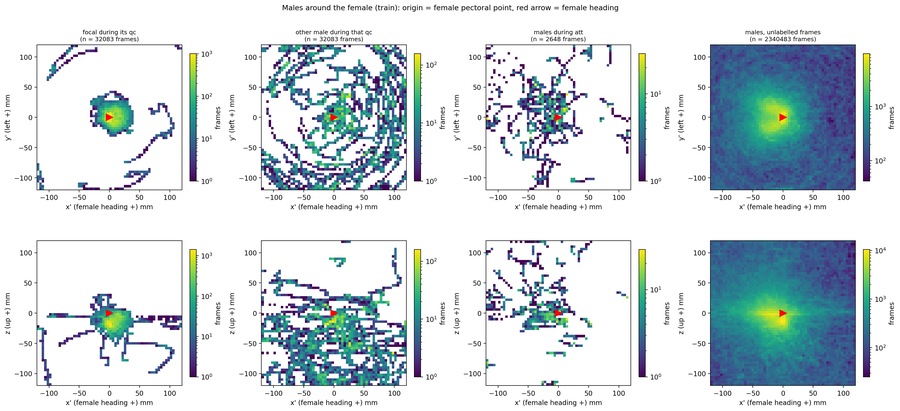

  fig figures/01_female_tank_position__all__base__train.png


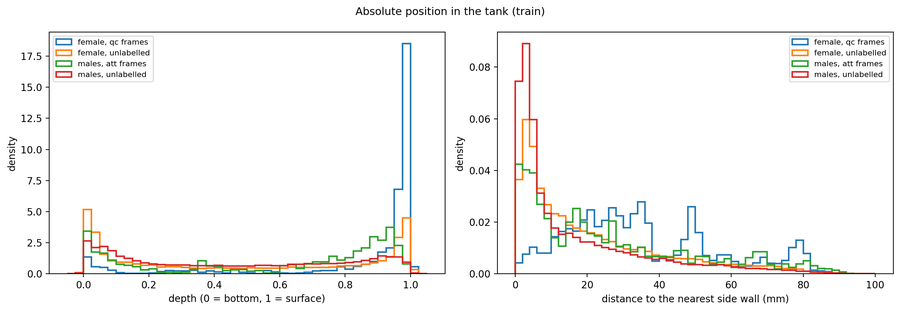

  csv data/01_tank_position__all__base__train.csv  rows 4
             group  frames  median depth (0 bottom, 1 surface)  % in top 20%  median wall distance mm  % within 15 mm of a wall
 female, qc frames   32083                                0.97         81.08                31.620001                     15.39
female, unlabelled 1129871                                0.46         32.93                13.620000                     52.67
 males, att frames    2648                                0.75         44.22                18.209999                     42.41
 males, unlabelled 2340483                                0.43         23.44                 7.090000                     64.88


In [6]:
# Step 1: where the two males are around the female; where the fish are in the tank (train).
D = DATA["train"]
lim = 120
cols = [("focal during its qc", (D["y_qc"] == 1), "focal"), ("other male during that qc", (D["y_qc"] == 1), "rival"),
        ("males during att", (D["y_att"] == 1), "focal"), ("males, unlabelled frames", (D["y_qc"] == 0) & (D["y_att"] == 0), "focal")]
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
for j, (title, m, who) in enumerate(cols):
    n = int(m.sum())
    for i, (a, b, lab) in enumerate((("x", "y", "y' (left +)"), ("x", "z", "z (up +)"))):
        ax = axes[i, j]
        xa, ya = D[f"{who}_{a}F"][m], D[f"{who}_{b}F"][m]
        ok = np.isfinite(xa) & np.isfinite(ya)
        hb = ax.hist2d(xa[ok], ya[ok], bins=60, range=[[-lim, lim], [-lim, lim]], norm=LogNorm(), cmap="viridis")
        ax.plot(0, 0, marker=">", color="r", ms=10)
        ax.set_aspect("equal")
        ax.set_xlabel("x' (female heading +) mm")
        ax.set_ylabel(lab + " mm")
        ax.set_title(f"{title}\n(n = {n} frames)" if i == 0 else "", fontsize=9)
        fig.colorbar(hb[3], ax=ax, fraction=0.04, label="frames")
fig.suptitle("Males around the female (train): origin = female pectoral point, red arrow = female heading", fontsize=11)
fig.tight_layout()
show(L.save_fig(fig, "01", "positions_female_frame", "all", "base", "train"))

wall = lambda x, y: np.min(np.column_stack([x - XY_LO[0], XY_HI[0] - x, y - XY_LO[1], XY_HI[1] - y]), axis=1)
F_depth, F_wall = D["depth"], wall(D["F_x"], D["F_y"])
m_depth = (D["focal_z"] - Z_LO) / (Z_HI - Z_LO)
m_wall = wall(D["focal_x"], D["focal_y"])
c0 = D["copy"] == 0
groups = {"female, qc frames": ((D["y_qc"] == 1), F_depth, F_wall),
          "female, unlabelled": ((D["y_qc"] == 0) & (D["y_att"] == 0) & c0, F_depth, F_wall),
          "males, att frames": ((D["y_att"] == 1), m_depth, m_wall),
          "males, unlabelled": ((D["y_qc"] == 0) & (D["y_att"] == 0), m_depth, m_wall)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rows = []
for name, (m, dep, wl) in groups.items():
    ok = m & np.isfinite(dep) & np.isfinite(wl)
    axes[0].hist(dep[ok], bins=np.linspace(-0.05, 1.05, 45), density=True, histtype="step", lw=1.6, label=name)
    axes[1].hist(wl[ok], bins=np.linspace(0, 100, 51), density=True, histtype="step", lw=1.6, label=name)
    rows.append({"group": name, "frames": int(ok.sum()), "median depth (0 bottom, 1 surface)": np.median(dep[ok]),
                 "% in top 20%": 100 * (dep[ok] > 0.8).mean(), "median wall distance mm": np.median(wl[ok]),
                 "% within 15 mm of a wall": 100 * (wl[ok] < 15).mean()})
axes[0].set_xlabel("depth (0 = bottom, 1 = surface)")
axes[1].set_xlabel("distance to the nearest side wall (mm)")
for ax in axes:
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
fig.suptitle("Absolute position in the tank (train)", fontsize=11)
fig.tight_layout()
show(L.save_fig(fig, "01", "female_tank_position", "all", "base", "train"))
TANK = pd.DataFrame(rows)
L.save_csv(TANK, "01", "tank_position", "all", "base", "train")
print(TANK.round(2).to_string(index=False))

## Step 2 — 打分流程（公共函数）

- **状态编码**：每个变量按参数分档（多一个"未定义"档），各方法的每一级回退 = 一个变量组合的混合进制编码（`level_code`）。无效帧（审核不可用、三鱼不全）在所有级别都是同一个"无状态"单位。
- **B**：v3b 微状态（一级，向整体比例收缩，同 v6）。**B+rot**：两级 [B × rot, B]。
- **T 系列**：`qc_levels` / `att_levels` 给出的五级回退（`backoff_scores`）。
- **C**：Infomap 只在训练集完整状态（qc：T+rot；攻击：T 或 T+seq）的转移矩阵上跑（每个副本内的连续有效段，τ 帧后的转移，保留自环，行归一化，`N_TRIALS` 次）。测试中训练里没出现过的状态，按回退级别找训练中同一上级状态里帧数最多的簇（`backoff_majority`）。簇分数 = P(类别 | 簇) 向整体比例收缩。
- **LOEO 选择**（回转角窗口、时间顺序窗口、τ）：在训练集里每次留出一个录像，用其余录像拟合分数，在留出录像上算 AP（平滑后，评估副本），取 4 个录像平均 AP 最高的。Infomap 不用标签，所以簇本身用全部训练集一次算好。
- **平滑** qc 124 帧、攻击 5 帧（副本内居中平均）；**阈值** = 训练集 F1 最大；**相同误报率**：在训练集上找误报 / 配对·分钟 ≤ 0.25 / 0.5 / 1 的最低阈值。
- **阈值用交叉预测的训练分数选**（冒烟测试后的修正）：三鱼状态很细，用同一批训练帧既打分又选阈值会过拟合（冒烟测试中 T 的训练 F1 达 0.93–0.95，选出的阈值在测试集上召回偏低，固定误报率的阈值在测试集上的误报是目标的 2–3 倍）。所以每个训练录像的分数由其余训练录像拟合（同 LOEO），阈值在这些分数上选；测试集的分数仍由全部训练集拟合。所有方法（包括 B）都这样做。
- **攻击的回退链**：雄–雄变量和两条雄鱼的速度保留到最后；时间顺序变量最后分两步去掉（先保留 lead / who / dmin / turn，再保留 who / dmin），最末一级 = 雄–雄距离 + 两条雄鱼速度。

In [7]:
# Step 2 (setup): state codes, back-off scoring, LOEO selection, Infomap, evaluation.
def bins_of(D, rot_key=None, seq_w=None):
    b, w = {}, {}
    for k, (kind, edges) in TRIO_SPECS.items():
        b[k], w[k] = TS.bin_values(D[k], kind, edges)
    if rot_key is not None:
        b["rot"], w["rot"] = TS.bin_values(D[rot_key], "lin", ROT_EDGES)
    b["depth"], w["depth"] = TS.bin_values(D["depth"], "lin", DEPTH_EDGES)
    if seq_w is not None:
        for k, (kind, edges) in SEQ_SPECS.items():
            b[k], w[k] = TS.bin_values(D[f"{k}_{seq_w}"], kind, edges)
    return b, w


def method_levels(target, spec):
    return (qc_levels if target == "qc" else att_levels)(spec["extra"])


def codes_for(D, target, key, sel):
    # list of per-frame codes, finest level first; -1 = no state (same unit at every level)
    spec = METHODS[target][key]
    bad = ~D["valid"]
    if spec["kind"] == "B":
        st = D[f"B_{target}"].astype(np.int64)
        lv = [st]
        if "rot" in spec["extra"]:
            rb, rw = TS.bin_values(D[f"rot_{sel['rot']}"], "lin", ROT_EDGES)
            lv = [st * rw + rb, st]
        return [np.where(bad | (st < 0), -1, c) for c in lv]
    b, w = bins_of(D, f"rot_{sel['rot']}" if sel.get("rot") is not None else None, sel.get("seq"))
    levels = method_levels(target, spec)
    TS.check_nested(levels)
    return [np.where(bad, -1, TS.level_code(b, w, keys)) for keys in levels]


def eval_mask(D, target):
    return np.isin(D["copy"], EVAL_COPIES[target])


def smooth(D, s, target):
    return P4.rolling_mean_blocks(s, D["block"], SMOOTH[target])


def ap_of(y, s):
    ok = y >= 0
    return float(average_precision_score(y[ok], s[ok])) if (y[ok] == 1).any() else np.nan


def cv_scores(fit_apply):
    # cross-fitted train scores: each training experiment scored by a fit on the other ones
    D = DATA["train"]
    s = np.full(len(D["frame"]), np.nan)
    for ei in range(len(D["exp_names"])):
        ho = D["exp"] == ei
        s[ho] = fit_apply(~ho, ho)
    return s


def loeo_ap(target, fit_apply, cv=None):
    # AP of every held-out training experiment; fit_apply(fit_rows, apply_rows) -> raw scores of apply_rows
    D = DATA["train"]
    y = D[f"y_{target}"]
    sm = smooth(D, cv_scores(fit_apply) if cv is None else cv, target)
    m = eval_mask(D, target)
    return [ap_of(y[(D["exp"] == ei) & m], sm[(D["exp"] == ei) & m]) for ei in range(len(D["exp_names"]))]


def backoff_fit_apply(codes, y):
    def f(fit, app):
        _s, s_app, _u = TS.backoff_scores([c[fit] for c in codes], y[fit], [c[app] for c in codes], PRIOR_FRAMES)
        return s_app
    return f


def minutes_of(D, m):
    return float(sum((m & (D["exp"] == i)).sum() / FPS_OF[e] / 60.0 for i, e in enumerate(D["exp_names"])))


# ------------------------------------------------------------------ Infomap
def segments(D, st):
    ok = st >= 0
    start = ok.copy()
    start[1:] = ok[1:] & (~ok[:-1] | (D["block"][1:] != D["block"][:-1]))
    seg = np.cumsum(start) - 1
    return np.where(ok, seg, -1)


def infomap_jobs(target, codes_tr0):
    u, inv = np.unique(codes_tr0[codes_tr0 >= 0], return_inverse=True)
    st = np.full(len(codes_tr0), -1, np.int64)
    st[codes_tr0 >= 0] = inv
    seg = segments(DATA["train"], st)
    jobs = {}
    for tau in TAUS:
        counts, n_pairs = S.transition_counts(st, seg, int(tau), len(u))
        prob = S.row_normalize(counts)
        jobs[tau] = (prob, n_pairs)
        print(f"[{target}] tau {tau}: {len(u)} states, {prob.nnz} edges, {n_pairs} transitions", flush=True)
    return u, st, jobs


def relabel_by_frames(raw, st):
    k = int(raw.max()) + 1
    cover = np.bincount(raw[st[st >= 0]], minlength=k)
    order = np.lexsort((np.arange(k), -cover))
    new = np.empty(k, np.int64)
    new[order] = np.arange(k)
    return new[raw]


# ------------------------------------------------------------------ evaluation
def evaluate(target, key, s_te, thr, thr_fa, thr_in):
    D = DATA["test"]
    y = D[f"y_{target}"]
    rows = []
    for ei, e in enumerate(D["exp_names"]):
        m = (D["exp"] == ei) & eval_mask(D, target)
        yy, ss, bb = y[m], s_te[m], D["block"][m]
        lab = yy >= 0
        mins = minutes_of(D, m & (y >= 0))
        row = {"video": exp_short(e), "method": key, "pos_frames": int((yy == 1).sum()), "labelled_frames": int(lab.sum()),
               "pos_rate": float((yy[lab] == 1).mean()), "AP": ap_of(yy, ss), "pair_minutes": mins}
        for tag, t in [("", thr)] + [(f"@FA{fa}", thr_fa[fa]) for fa in FA_TARGETS] + [("@insampleF1", thr_in)]:
            pred = ss >= t
            tp, fp = int((pred & (yy == 1)).sum()), int((pred & (yy == 0)).sum())
            good, counted = TS.alarm_counts(yy, pred, bb)
            f, n = TS.bouts_found(yy, pred, bb)
            row.update({f"precision{tag}": tp / max(tp + fp, 1), f"recall{tag}": tp / max(int((yy == 1).sum()), 1),
                        f"bouts_found{tag}": f, f"bouts{tag}": n, f"false_alarm_intervals{tag}": counted - good,
                        f"false_alarms_per_min{tag}": (counted - good) / max(mins, 1e-9), f"threshold{tag}": t})
        rows.append(row)
    return rows


RESULTS = {}
print("methods:", {t: list(METHODS[t]) for t in TARGETS})

methods: {'att': ['B', 'T', 'T+seq', 'C']}


## Step 1c — 状态覆盖：每一级回退解决了多少帧

对每个 T 系列方法（回转角窗口暂用 1 s，只影响含 rot 的方法），训练集上"至少有 50 个有标签训练帧"的状态覆盖了多少帧，以及测试帧（全部 / 正例）分别在哪一级拿到足够数据（`backoff_scores` 的 `used`）。B（v3b 配对微状态）作参照。

  csv data/01c_backoff_coverage__all__base__test.csv  rows 18
target method                            level  test frames %  test positive frames %  states seen in train
   att      B                                0           89.2                    38.0               14113.0
   att      B none (<50 frames at every level)           10.8                    62.0                   NaN
   att      T                                0           22.4                    10.5              139076.0
   att      T                                1            6.0                     1.1              119604.0
   att      T                                2           37.3                    17.3               48675.0
   att      T                                3           32.3                    63.3                3187.0
   att      T                                4            1.9                     7.1                 300.0
   att      T                                5            0.1             

  fig figures/01c_backoff_coverage__all__base__test.png


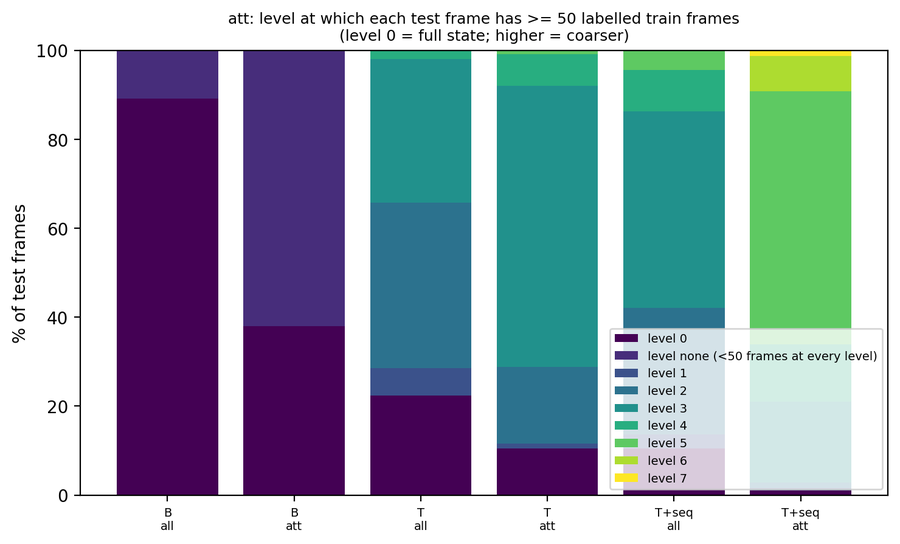

In [8]:
# Step 1c: how much of the data each back-off level resolves.
rows = []
for target in TARGETS:
    sel = {"rot": 1.0, "seq": SEQ_WINDOWS_S[1] if USE_SEQ else None}
    ytr = DATA["train"][f"y_{target}"]
    yte = DATA["test"][f"y_{target}"]
    for key, spec in METHODS[target].items():
        if spec["kind"] == "C":
            continue
        ctr, cte = codes_for(DATA["train"], target, key, sel), codes_for(DATA["test"], target, key, sel)
        _a, _b, used = TS.backoff_scores(ctr, ytr, cte, PRIOR_FRAMES)
        ok = (cte[0] >= 0) & (yte >= 0)
        for lvl in range(len(ctr) + 1):
            rows.append({"target": target, "method": key, "level": lvl if lvl < len(ctr) else "none (<50 frames at every level)",
                         "test frames %": 100 * float((used[ok] == lvl).mean()),
                         "test positive frames %": 100 * float((used[ok & (yte == 1)] == lvl).mean()) if (ok & (yte == 1)).any() else np.nan,
                         "states seen in train": len(np.unique(ctr[lvl][ctr[lvl] >= 0])) if lvl < len(ctr) else np.nan})
COVER = pd.DataFrame(rows)
L.save_csv(COVER, "01c", "backoff_coverage", "all", "base", "test")
print(COVER.round(1).to_string(index=False))
fig, axes = plt.subplots(1, len(TARGETS), figsize=(7.5 * len(TARGETS), 4.6), squeeze=False)
for ax, target in zip(axes[0], TARGETS):
    c = COVER[COVER.target == target]
    meths = list(dict.fromkeys(c.method))
    levels = list(dict.fromkeys(c.level))
    bottom = np.zeros(2 * len(meths))
    cmap = plt.get_cmap("viridis", len(levels))
    for li, lvl in enumerate(levels):
        vals = []
        for mth in meths:
            r = c[(c.method == mth) & (c.level == lvl)]
            vals += [float(r["test frames %"].iloc[0]) if len(r) else 0.0, float(r["test positive frames %"].iloc[0]) if len(r) else 0.0]
        vals = np.nan_to_num(np.array(vals))
        ax.bar(np.arange(len(vals)), vals, bottom=bottom, color=cmap(li), label=f"level {lvl}")
        bottom += vals
    ax.set_xticks(np.arange(2 * len(meths)), [f"{m}\n{w}" for m in meths for w in ("all", target)], fontsize=7)
    ax.set_ylabel("% of test frames")
    ax.set_title(f"{target}: level at which each test frame has >= {PRIOR_FRAMES:.0f} labelled train frames\n"
                 "(level 0 = full state; higher = coarser)", fontsize=9)
    ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
show(L.save_fig(fig, "01c", "backoff_coverage", "all", "base", "test"))

## Step 2a — 选窗口（训练集 LOEO）

- qc：主角累积回转角的窗口（0.5 / 1 / 2 s），按 **B+rot** 的 LOEO 平均 AP 选，T+rot、T+rot+depth、C 用同一个窗口。
- 攻击：时间顺序变量的窗口（50 / 100 / 200 ms），按 **T+seq** 的 LOEO 平均 AP 选，C 用同一个窗口。

In [9]:
# Step 2a: windows chosen on train (leave one training experiment out).
SEL = {}
rows = []
if "qc" in TARGETS:
    y = DATA["train"]["y_qc"]
    for w_s in ROT_WINDOWS_S:
        aps = loeo_ap("qc", backoff_fit_apply(codes_for(DATA["train"], "qc", "B+rot", {"rot": w_s}), y))
        rows.append({"target": "qc", "method": "B+rot", "window_s": w_s, **{exp_short(e): a for e, a in zip(TRAIN_EXPERIMENTS, aps)},
                     "mean_LOEO_AP": float(np.nanmean(aps))})
        print(f"qc rot window {w_s} s: LOEO AP {np.round(aps, 3)} mean {np.nanmean(aps):.3f}", flush=True)
    best = max((r for r in rows if r["target"] == "qc"), key=lambda r: r["mean_LOEO_AP"])
    SEL["qc"] = {"rot": best["window_s"]}
if "att" in TARGETS:
    SEL["att"] = {}
    if USE_SEQ:
        y = DATA["train"]["y_att"]
        for w_s in SEQ_WINDOWS_S:
            aps = loeo_ap("att", backoff_fit_apply(codes_for(DATA["train"], "att", "T+seq", {"seq": w_s}), y))
            rows.append({"target": "att", "method": "T+seq", "window_s": w_s, **{exp_short(e): a for e, a in zip(TRAIN_EXPERIMENTS, aps)},
                         "mean_LOEO_AP": float(np.nanmean(aps))})
            print(f"att time-order window {w_s} s: LOEO AP {np.round(aps, 3)} mean {np.nanmean(aps):.3f}", flush=True)
        best = max((r for r in rows if r["target"] == "att"), key=lambda r: r["mean_LOEO_AP"])
        SEL["att"] = {"seq": best["window_s"]}
WINDOWS = pd.DataFrame(rows)
if len(WINDOWS):
    L.save_csv(WINDOWS, "02a", "window_choice", "all", "base", "train")
    print(WINDOWS.round(3).to_string(index=False))
print("chosen:", SEL)
L.update_params("chosen", {"windows": SEL})

att time-order window 0.05 s: LOEO AP [0.069 0.13  0.644 0.377] mean 0.305


att time-order window 0.1 s: LOEO AP [0.133 0.165 0.658 0.412] mean 0.342


att time-order window 0.2 s: LOEO AP [0.142 0.196 0.57  0.354] mean 0.316


  csv data/02a_window_choice__all__base__train.csv  rows 3
target method  window_s  K_1_1  K_1_2  P_1_1  P_1_2  mean_LOEO_AP
   att  T+seq      0.05  0.069  0.130  0.644  0.377         0.305
   att  T+seq      0.10  0.133  0.165  0.658  0.412         0.342
   att  T+seq      0.20  0.142  0.196  0.570  0.354         0.316
chosen: {'att': {'seq': 0.1}}


{'parameters': {'VARIANT': 'v7b',
  'RUN_NAME': '20261110_trio_attack_sequence_v7b',
  'SOURCE_RUN': '20261108_pair_state6d_clean_sw11_v3b',
  'OUTPUT_ROOT': None,
  'TRAIN_EXPERIMENTS': ['20251225_K_1_1_FCMC',
   '20251225_K_1_2_FCMC',
   '20260112_P_1_1_FCMC',
   '20260113_P_1_2_FCMC'],
  'TEST_EXPERIMENTS': ['20251225_K_1_3_FCMC',
   '20260112_P_1_3_FCMC',
   '20251220_E_1_1_FCMC',
   '20251220_E_1_2_FCMC',
   '20251220_E_1_3_FCMC'],
  'REVIEW_MIN_WATCHED_PCT': 99.0,
  'TARGETS': ['att'],
  'USE_SEQ': True,
  'DPI': 200,
  'THUMB_WIDTH': 900,
  'LABEL_CLASSES': {'wrap': ['wrap'],
   'qc': ['quick circle', 'incomplete qc', 'courtship'],
   'att': ['attack', 'attempted att', 'dash']},
  'COPIES': [['M1', 'M2'], ['M2', 'M1']],
  'EVAL_COPIES': {'qc': [0, 1], 'att': [0]},
  'D_EDGES': [0, 10, 20, 40, inf],
  'DZ_EDGES': [-inf, -20, 20, inf],
  'SP_EDGES': [0, 60, inf],
  'MD_EDGES': [0, 15, 40, inf],
  'TRIO_SPECS': {'fD': ['lin', [0, 10, 20, 40, inf]],
   'fdz': ['lin', [-inf, -20, 20,

## Step 2b — Infomap（C）与 τ 的选择

在训练集完整状态的转移矩阵上跑 Infomap（τ = 7、17；每个 `N_TRIALS` = 200 次）。结果存成 `data/02b_infomap__<target>__tau<τ>…npz`；同参数的文件已存在时直接读（重跑 notebook 不必重算）。τ 按 C 的训练集 LOEO 平均 AP 选。

In [10]:
# Step 2b: Infomap on the full training states; tau chosen by LOEO AP of the cluster scores.
CLUST = {}
pending = []
for target in TARGETS:
    on = METHODS[target]["C"]["on"]
    ctr = codes_for(DATA["train"], target, on, SEL[target])
    u, st, jobs = infomap_jobs(target, ctr[0])
    CLUST[target] = {"on": on, "u": u, "st": st, "codes_tr": ctr, "labels": {}}
    for tau, (prob, n_pairs) in jobs.items():
        p = {"on": on.replace("+", "_"), "tau": tau, "trials": N_TRIALS, **{k: v for k, v in SEL[target].items()}}
        path = L.path("02b", "infomap", target, p, "train", "npz")
        if path.exists():
            z = L.load_npz("02b", "infomap", target, p, "train")
            if len(z["codes"]) == len(u) and np.array_equal(z["codes"], u):
                CLUST[target]["labels"][tau] = z["cluster"]
                print(f"[{target}] tau {tau}: clusters read from {path.name}")
                continue
        pending.append((target, tau, prob, p))
if pending:
    backend = S.resolve_infomap_backend()["backend"]
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=INFOMAP_WORKERS) as ex:
        fut = {(t, tau): ex.submit(S.run_infomap, prob, N_TRIALS, INFOMAP_SEED, backend) for t, tau, prob, _p in pending}
        res = {k: f.result() for k, f in fut.items()}
    print(f"{len(pending)} Infomap runs x {N_TRIALS} trials: {(time.time() - t0) / 60:.1f} min")
    for t, tau, _prob, p in pending:
        lab = relabel_by_frames(np.asarray(res[(t, tau)][0], np.int64), CLUST[t]["st"])
        CLUST[t]["labels"][tau] = lab
        L.save_npz({"codes": CLUST[t]["u"], "cluster": lab, "codelength": np.array(res[(t, tau)][1])},
                   "02b", "infomap", t, p, "train")


def cluster_rows(target, tau, D, codes):
    # per-frame cluster; no-state frames -> k; states unseen in train -> back-off majority; -1 if nothing matches
    C = CLUST[target]
    lab = C["labels"][tau]
    k = int(lab.max()) + 1
    tr_cl = np.where(C["st"] >= 0, lab[np.clip(C["st"], 0, None)], -1)
    if D is DATA["train"]:
        out = tr_cl
    else:
        okc = codes[0] >= 0
        out = np.full(len(codes[0]), -1, np.int64)
        out[okc] = TS.backoff_majority([c[C["st"] >= 0] for c in C["codes_tr"]], tr_cl[C["st"] >= 0], [c[okc] for c in codes])
    return np.where(codes[0] < 0, k, out), k + 1


rows = []
for target in TARGETS:
    y = DATA["train"][f"y_{target}"]
    C = CLUST[target]
    for tau in TAUS:
        cl, n = cluster_rows(target, tau, DATA["train"], C["codes_tr"])
        def fa(fit, app, cl=cl, n=n):
            sc = P4.cluster_scores(cl[fit], y[fit], n, PRIOR_FRAMES)
            return P4.frame_scores(cl[app], sc, float((y[fit][y[fit] >= 0] == 1).mean()))
        aps = loeo_ap(target, fa)
        sizes = np.bincount(cl[cl < n - 1], minlength=n - 1)
        rows.append({"target": target, "tau": tau, "clusters": n - 1, "largest_cluster_frames_%": 100 * sizes.max() / sizes.sum(),
                     "clusters_with_>=1000_frames": int((sizes >= 1000).sum()),
                     **{exp_short(e): a for e, a in zip(TRAIN_EXPERIMENTS, aps)}, "mean_LOEO_AP": float(np.nanmean(aps))})
TAU_TAB = pd.DataFrame(rows)
L.save_csv(TAU_TAB, "02b", "tau_choice", "all", "base", "train")
print(TAU_TAB.round(3).to_string(index=False))
for target in TARGETS:
    t = TAU_TAB[TAU_TAB.target == target]
    SEL[target]["tau"] = int(t.loc[t.mean_LOEO_AP.idxmax(), "tau"])
print("chosen:", SEL)
L.update_params("chosen", {"windows_and_tau": SEL})

[att] tau 7: 269261 states, 651814 edges, 2650404 transitions


[att] tau 17: 269261 states, 676113 edges, 2645912 transitions


2 Infomap runs x 200 trials: 25.9 min
  npz data/02b_infomap__att__onT_seq-tau7-trials200-seq0.1__train.npz
  npz data/02b_infomap__att__onT_seq-tau17-trials200-seq0.1__train.npz


  csv data/02b_tau_choice__all__base__train.csv  rows 2
target  tau  clusters  largest_cluster_frames_%  clusters_with_>=1000_frames  K_1_1  K_1_2  P_1_1  P_1_2  mean_LOEO_AP
   att    7     27277                     0.089                           22  0.002  0.003  0.002  0.001         0.002
   att   17     20014                     0.090                           31  0.002  0.002  0.002  0.002         0.002
chosen: {'att': {'seq': 0.1, 'tau': 7}}


{'parameters': {'VARIANT': 'v7b',
  'RUN_NAME': '20261110_trio_attack_sequence_v7b',
  'SOURCE_RUN': '20261108_pair_state6d_clean_sw11_v3b',
  'OUTPUT_ROOT': None,
  'TRAIN_EXPERIMENTS': ['20251225_K_1_1_FCMC',
   '20251225_K_1_2_FCMC',
   '20260112_P_1_1_FCMC',
   '20260113_P_1_2_FCMC'],
  'TEST_EXPERIMENTS': ['20251225_K_1_3_FCMC',
   '20260112_P_1_3_FCMC',
   '20251220_E_1_1_FCMC',
   '20251220_E_1_2_FCMC',
   '20251220_E_1_3_FCMC'],
  'REVIEW_MIN_WATCHED_PCT': 99.0,
  'TARGETS': ['att'],
  'USE_SEQ': True,
  'DPI': 200,
  'THUMB_WIDTH': 900,
  'LABEL_CLASSES': {'wrap': ['wrap'],
   'qc': ['quick circle', 'incomplete qc', 'courtship'],
   'att': ['attack', 'attempted att', 'dash']},
  'COPIES': [['M1', 'M2'], ['M2', 'M1']],
  'EVAL_COPIES': {'qc': [0, 1], 'att': [0]},
  'D_EDGES': [0, 10, 20, 40, inf],
  'DZ_EDGES': [-inf, -20, 20, inf],
  'SP_EDGES': [0, 60, inf],
  'MD_EDGES': [0, 15, 40, inf],
  'TRIO_SPECS': {'fD': ['lin', [0, 10, 20, 40, inf]],
   'fdz': ['lin', [-inf, -20, 20,

## Step 3 — 拟合全部方法、在测试集上评估

每个目标、每个方法：在全部训练集上拟合分数（用于测试集）；训练集交叉预测分数 → 平滑 → 阈值（F1 最大；以及误报 / 配对·分钟 = 0.25、0.5、1）→ 测试集固定使用。打印的 F1 是交叉预测的训练 F1。另附 v6 式阈值（训练分数和阈值用同一批帧）的结果（`@insampleF1` 列），只用来和 v6 对照。

**表**（`data/03_results__<target>`）：每个测试录像、每个方法的 AP、帧精确率、帧召回率、检出 bout / bout、误报区间 / 配对·分钟（F1 阈值）；`@FA0.25` 等列 = 训练集定到该误报率的阈值下的同样指标。

In [11]:
# Step 3: fit every method on train, evaluate on test.
for target in TARGETS:
    Dtr, Dte = DATA["train"], DATA["test"]
    ytr = Dtr[f"y_{target}"]
    m_tr = eval_mask(Dtr, target)
    mins_tr = minutes_of(Dtr, m_tr & (ytr >= 0))
    rows, S_TE, FIT = [], {}, {}
    for key, spec in METHODS[target].items():
        t0 = time.time()
        if spec["kind"] == "C":
            tau = SEL[target]["tau"]
            cl_tr, n = cluster_rows(target, tau, Dtr, CLUST[target]["codes_tr"])
            cl_te, _n = cluster_rows(target, tau, Dte, codes_for(Dte, target, spec["on"], SEL[target]))
            sc = P4.cluster_scores(cl_tr, ytr, n, PRIOR_FRAMES)
            base = float((ytr[ytr >= 0] == 1).mean())
            s_te, s_in = P4.frame_scores(cl_te, sc, base), P4.frame_scores(cl_tr, sc, base)

            def fit_apply(fit, app, cl=cl_tr, n=n):
                scf = P4.cluster_scores(cl[fit], ytr[fit], n, PRIOR_FRAMES)
                return P4.frame_scores(cl[app], scf, float((ytr[fit][ytr[fit] >= 0] == 1).mean()))
            extra = f"Infomap on {spec['on']}, tau {tau}, unmatched test frames {int((cl_te < 0).sum())}"
        else:
            ctr, cte = codes_for(Dtr, target, key, SEL[target]), codes_for(Dte, target, key, SEL[target])
            s_in, s_te, used = TS.backoff_scores(ctr, ytr, cte, PRIOR_FRAMES)
            fit_apply = backoff_fit_apply(ctr, ytr)
            extra = f"{len(ctr)} levels"
        # thresholds from cross-fitted train scores (each training video scored by a fit on the others)
        sm_tr, sm_te = smooth(Dtr, cv_scores(fit_apply), target), smooth(Dte, s_te, target)
        thr, f1 = P4.best_f1_threshold(sm_tr[m_tr], ytr[m_tr])
        # v6-style threshold (train scores fitted on the same frames), kept for comparison with v6
        thr_in, f1_in = P4.best_f1_threshold(smooth(Dtr, s_in, target)[m_tr], ytr[m_tr])
        curve_tr = TS.alarm_curve(sm_tr[m_tr], ytr[m_tr], Dtr["block"][m_tr], mins_tr)
        thr_fa = {fa: TS.threshold_from_curve(curve_tr, fa) for fa in FA_TARGETS}
        S_TE[key] = sm_te
        FIT[key] = {"threshold": thr, "f1_train": f1, "thr_fa": thr_fa, "threshold_insample": thr_in, "f1_insample": f1_in}
        rows += evaluate(target, key, sm_te, thr, thr_fa, thr_in)
        print(f"[{target}] {key}: {extra}; cross-fitted train F1 {f1:.3f}, threshold {thr:.4f}; "
              f"in-sample train F1 {f1_in:.3f}, threshold {thr_in:.4f} ({time.time() - t0:.0f} s)", flush=True)
    res = pd.DataFrame(rows)
    RESULTS[target] = {"table": res, "scores": S_TE, "fit": FIT}
    L.save_csv(res, "03", "results", target, {k: v for k, v in SEL[target].items()}, "test")
    show_cols = ["video", "method", "AP", "pos_rate", "precision", "recall", "bouts_found", "bouts", "false_alarms_per_min"]
    print(f"\n{target}: train-F1 threshold")
    print(res[show_cols].round(3).to_string(index=False))
    for fa in FA_TARGETS:
        cols = ["video", "method", f"bouts_found@FA{fa}", f"bouts@FA{fa}", f"false_alarms_per_min@FA{fa}", f"recall@FA{fa}", f"precision@FA{fa}"]
        print(f"\n{target}: threshold set on train to {fa} false alarms / pair-min")
        print(res[cols].round(3).to_string(index=False))
    cols = ["video", "method", "precision@insampleF1", "recall@insampleF1", "bouts_found@insampleF1", "false_alarms_per_min@insampleF1"]
    print(f"\n{target}: v6-style threshold (best F1 on in-sample train scores), for comparison with v6")
    print(res[cols].round(3).to_string(index=False))

[att] B: 1 levels; cross-fitted train F1 0.123, threshold 0.0251; in-sample train F1 0.366, threshold 0.0567 (7 s)


[att] T: 6 levels; cross-fitted train F1 0.120, threshold 0.0996; in-sample train F1 0.680, threshold 0.1130 (14 s)


[att] T+seq: 8 levels; cross-fitted train F1 0.385, threshold 0.1974; in-sample train F1 0.763, threshold 0.1887 (17 s)


[att] C: Infomap on T+seq, tau 7, unmatched test frames 0; cross-fitted train F1 0.004, threshold 0.0010; in-sample train F1 0.628, threshold 0.1572 (6 s)


  csv data/03_results__att__seq0.1-tau7__test.csv  rows 20

att: train-F1 threshold
video method    AP  pos_rate  precision  recall  bouts_found  bouts  false_alarms_per_min
K_1_3      B 0.020     0.000      0.023   0.611            8     10                11.847
P_1_3      B 0.280     0.002      0.226   0.563           20     35                 3.462
E_1_1      B   NaN     0.000      0.000   0.000            0      0                 6.815
E_1_2      B 0.018     0.001      0.032   0.151            1      8                 6.341
E_1_3      B 0.021     0.000      0.020   0.395            3      7                 6.903
K_1_3      T 0.025     0.000      0.039   0.295            4     10                 3.959
P_1_3      T 0.189     0.002      0.261   0.228            5     35                 1.272
E_1_1      T   NaN     0.000      0.000   0.000            0      0                 3.423
E_1_2      T 0.027     0.001      0.054   0.158            0      8                 3.503
E_1_3      T 0.0

## Step 4 — 图：老师要的表、PR 曲线、相同误报率下的 bout 检出

- **`04_main_table__<target>`**：每个指标一个面板（训练集 F1 阈值），每个测试录像一组柱子，每个方法一根。AP 面板的虚线 = 随机水平（正例帧比例）。
- **`04_pr__<target>`**：每个测试录像的精确率–召回率曲线，圆点 = 训练集阈值。
- **`04_bouts_vs_fa__<target>`**：每个测试录像，阈值从高到低扫一遍：横轴误报 / 配对·分钟，纵轴检出 bout 数（老师要的"同样误报数下能多拾多少 bout"）；三角 = 训练集定到 0.25 / 0.5 / 1 误报的阈值在测试集上的位置。

  fig figures/04_main_table__att__seq0.1-tau7__test.png


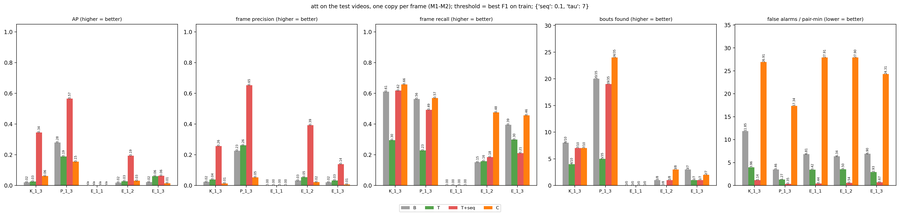

  fig figures/04_pr__att__seq0.1-tau7__test.png


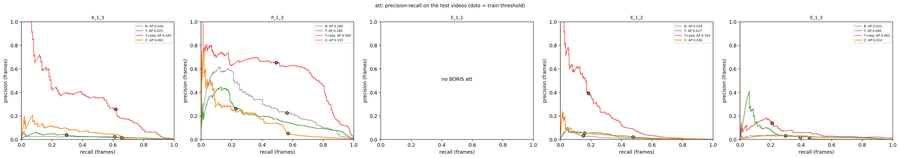

  fig figures/04_bouts_vs_fa__att__seq0.1-tau7__test.png


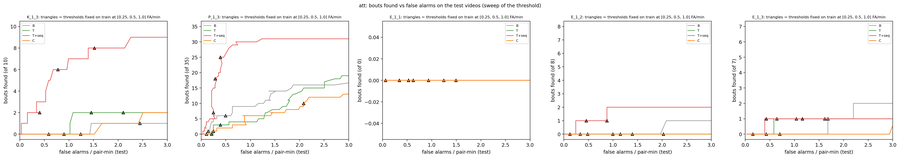

  csv data/04_bouts_vs_fa__att__seq0.1-tau7__test.csv  rows 4901


In [12]:
# Step 4: figures.
MAIN_METRICS = [("AP", "AP (higher = better)"), ("precision", "frame precision (higher = better)"),
                ("recall", "frame recall (higher = better)"), ("bouts_found", "bouts found (higher = better)"),
                ("false_alarms_per_min", "false alarms / pair-min (lower = better)")]
for target in TARGETS:
    res = RESULTS[target]["table"]
    meths = list(METHODS[target])
    vids = list(dict.fromkeys(res.video))
    tp = {k: v for k, v in SEL[target].items()}
    fig, axes = plt.subplots(1, len(MAIN_METRICS), figsize=(4.6 * len(MAIN_METRICS), 5.4))
    w = 0.8 / len(meths)
    for ax, (col, nm) in zip(axes, MAIN_METRICS):
        for mi, key in enumerate(meths):
            vals = [float(res[(res.video == v) & (res.method == key)][col].iloc[0]) for v in vids]
            x = np.arange(len(vids)) + (mi - (len(meths) - 1) / 2) * w
            ax.bar(x, np.nan_to_num(vals), width=w, color=METHOD_COLOR[key], label=key)
            for xi, v, vid in zip(x, vals, vids):
                if col == "bouts_found":
                    txt = f"{int(v)}/{int(res[(res.video == vid) & (res.method == key)]['bouts'].iloc[0])}"
                else:
                    txt = f"{v:.2f}" if np.isfinite(v) else "n/a"
                ax.text(xi, np.nan_to_num(v), txt, ha="center", va="bottom", fontsize=5.5, rotation=90)
        if col == "AP":
            for vi, v in enumerate(vids):
                ax.hlines(float(res[res.video == v]["pos_rate"].iloc[0]), vi - 0.4, vi + 0.4, color="k", ls=":", lw=1)
        if col in ("AP", "precision", "recall"):
            ax.set_ylim(0, 1.05)
        else:
            ax.set_ylim(0, max(ax.get_ylim()[1], 1) * 1.2)
        ax.set_xticks(np.arange(len(vids)), vids, fontsize=8)
        ax.set_title(nm, fontsize=9)
    h, lab = axes[0].get_legend_handles_labels()
    fig.legend(h, lab, loc="lower center", ncol=len(meths), fontsize=8)
    ev = "both copies (FM1 + FM2)" if target == "qc" else "one copy per frame (M1-M2)"
    fig.suptitle(f"{target} on the test videos, {ev}; threshold = best F1 on train; {SEL[target]}", fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    show(L.save_fig(fig, "04", "main_table", target, tp, "test"))

    D = DATA["test"]
    y = D[f"y_{target}"]
    fig, axes = plt.subplots(1, len(vids), figsize=(5.2 * len(vids), 4.6), squeeze=False)
    fig2, axes2 = plt.subplots(1, len(vids), figsize=(5.2 * len(vids), 4.6), squeeze=False)
    curves = []
    for ax, ax2, (ei, e) in zip(axes[0], axes2[0], enumerate(D["exp_names"])):
        m = (D["exp"] == ei) & eval_mask(D, target)
        yy, bb = y[m], D["block"][m]
        mins = minutes_of(D, m & (y >= 0))
        for key in meths:
            ss = RESULTS[target]["scores"][key][m]
            r = res[(res.video == exp_short(e)) & (res.method == key)].iloc[0]
            if (yy == 1).any():
                ok = yy >= 0
                p_, r_, _t = precision_recall_curve(yy[ok], ss[ok])
                ax.plot(r_, p_, color=METHOD_COLOR[key], lw=1.3, label=f"{key}: AP {r.AP:.3f}")
                ax.plot(r.recall, r.precision, "o", color=METHOD_COLOR[key], mec="k", ms=6)
            c = TS.alarm_curve(ss, yy, bb, mins)
            c["video"], c["method"] = exp_short(e), key
            curves.append(c)
            ax2.plot(c.false_alarms_per_min, c.bouts_found, color=METHOD_COLOR[key], lw=1.3, label=key)
            for fa in FA_TARGETS:
                ax2.plot(r[f"false_alarms_per_min@FA{fa}"], r[f"bouts_found@FA{fa}"], "^", color=METHOD_COLOR[key], mec="k", ms=6)
        n_b = int(res[res.video == exp_short(e)]["bouts"].iloc[0])
        if (yy == 1).any():
            ax.axhline(float((yy[yy >= 0] == 1).mean()), color="0.7", ls=":", lw=1)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.legend(fontsize=6.5, loc="upper right")
        else:
            ax.text(0.5, 0.5, f"no BORIS {target}", ha="center", transform=ax.transAxes)
        ax.set_xlabel("recall (frames)")
        ax.set_ylabel("precision (frames)")
        ax.set_title(f"{exp_short(e)}", fontsize=9)
        ax2.set_xlim(0, 3)
        ax2.set_xlabel("false alarms / pair-min (test)")
        ax2.set_ylabel(f"bouts found (of {n_b})")
        ax2.set_title(f"{exp_short(e)}: triangles = thresholds fixed on train at {FA_TARGETS} FA/min", fontsize=8)
        ax2.legend(fontsize=7)
    fig.suptitle(f"{target}: precision-recall on the test videos (dots = train threshold)", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "04", "pr", target, tp, "test"))
    fig2.suptitle(f"{target}: bouts found vs false alarms on the test videos (sweep of the threshold)", fontsize=10)
    fig2.tight_layout()
    show(L.save_fig(fig2, "04", "bouts_vs_fa", target, tp, "test"))
    L.save_csv(pd.concat(curves, ignore_index=True), "04", "bouts_vs_fa", target, tp, "test")

## Step 5 — 汇总

每个目标：所有测试录像合起来（bout 和误报区间相加），F1 阈值和三个固定误报率阈值下各方法检出的 bout。再列出输出文件。

In [13]:
# Step 5: totals over the test videos and the file list.
for target in TARGETS:
    res = RESULTS[target]["table"]
    agg = {"bouts": "sum", "bouts_found": "sum", "false_alarm_intervals": "sum", "pair_minutes": "sum"}
    for fa in FA_TARGETS:
        agg.update({f"bouts_found@FA{fa}": "sum", f"false_alarm_intervals@FA{fa}": "sum"})
    tot = res.groupby("method", sort=False).agg(agg).reset_index()
    tot["false_alarms_per_min"] = tot.false_alarm_intervals / tot.pair_minutes
    for fa in FA_TARGETS:
        tot[f"false_alarms_per_min@FA{fa}"] = tot[f"false_alarm_intervals@FA{fa}"] / tot.pair_minutes
    tot["mean_AP_over_videos_with_positives"] = res.groupby("method", sort=False)["AP"].mean().to_numpy()
    L.save_csv(tot, "05", "totals", target, {k: v for k, v in SEL[target].items()}, "test")
    print(f"\n{target}, all test videos together ({', '.join(dict.fromkeys(res.video))}):")
    print(tot.round(3).to_string(index=False))
print("\nskipped test videos:", SKIPPED or "none")
print("\nfiles:")
for p in sorted(L.root.rglob("*")):
    if p.is_file() and "thumbs" not in p.parts:
        print(" ", p.relative_to(L.root))

  csv data/05_totals__att__seq0.1-tau7__test.csv  rows 4

att, all test videos together (K_1_3, P_1_3, E_1_1, E_1_2, E_1_3):
method  bouts  bouts_found  false_alarm_intervals  pair_minutes  bouts_found@FA0.25  false_alarm_intervals@FA0.25  bouts_found@FA0.5  false_alarm_intervals@FA0.5  bouts_found@FA1.0  false_alarm_intervals@FA1.0  false_alarms_per_min  false_alarms_per_min@FA0.25  false_alarms_per_min@FA0.5  false_alarms_per_min@FA1.0  mean_AP_over_videos_with_positives
     B     60           32                   1136       158.631                   0                            58                  1                          100                  8                          226                 7.161                        0.366                       0.630                       1.425                               0.085
     T     60           10                    486       158.631                   1                           106                  4                          164        